In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import (
    CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
)
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)

CATEGORIES = ["sci.electronics", "rec.autos", "comp.sys.mac.hardware", "sci.med"]

raw_data = fetch_20newsgroups(
    subset="all",
    categories=CATEGORIES,
    remove=("headers", "footers", "quotes"),
)

df = pd.DataFrame(
    {
        "text": raw_data.data,
        "true_label": [raw_data.target_names[i] for i in raw_data.target],
    }
)
df = df[df["text"].str.strip().str.len() > 50].reset_index(drop=True)
print(f"Loaded {len(df)} unstructured user posts.")

Loaded 3703 unstructured user posts.


In [2]:
sample_post = df["text"].iloc[0][:400]
print("--- Raw Sample Post ---")
print(sample_post)
print("-" * 40)

tokens = [w.lower() for w in word_tokenize(sample_post) if w.isalpha()]

stop_words = set(stopwords.words("english"))
filtered_tokens = [w for w in tokens if w not in stop_words]

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()
stemmed_tokens = [stemmer.stem(w) for w in filtered_tokens]
lemmatized_tokens = [lemmatizer.lemmatize(w, pos="v") for w in filtered_tokens]

print("Filtered Tokens:  ", filtered_tokens[:12])
print("Stemmed Roots:    ", stemmed_tokens[:12])
print("Lemmatized Words: ", lemmatized_tokens[:12])

--- Raw Sample Post ---

My Honda has a cable release that can be locked out with the ignition key.
The valet key can be left with someone and will NOT unlock the trunk
or enable the cable release.
----------------------------------------
Filtered Tokens:   ['honda', 'cable', 'release', 'locked', 'ignition', 'key', 'valet', 'key', 'left', 'someone', 'unlock', 'trunk']
Stemmed Roots:     ['honda', 'cabl', 'releas', 'lock', 'ignit', 'key', 'valet', 'key', 'left', 'someon', 'unlock', 'trunk']
Lemmatized Words:  ['honda', 'cable', 'release', 'lock', 'ignition', 'key', 'valet', 'key', 'leave', 'someone', 'unlock', 'trunk']


TF-IDF Matrix Shape: (3703, 4000) | Sparsity: 99.04%


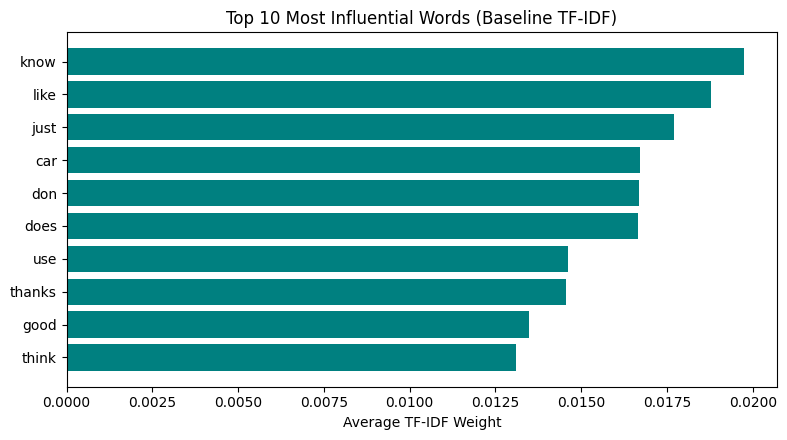

In [3]:
bow_vec = CountVectorizer(stop_words="english", max_features=4000, min_df=5)
tfidf_vec = TfidfVectorizer(stop_words="english", max_features=4000, min_df=5)

X_bow = bow_vec.fit_transform(df["text"])
X_tfidf = tfidf_vec.fit_transform(df["text"])

total_elements = X_tfidf.shape[0] * X_tfidf.shape[1]
sparsity = 100.0 * (1.0 - (X_tfidf.nnz / total_elements))
print(f"TF-IDF Matrix Shape: {X_tfidf.shape} | Sparsity: {sparsity:.2f}%")

tfidf_means = np.asarray(X_tfidf.mean(axis=0)).ravel()
top_idx = tfidf_means.argsort()[-10:]
top_words = tfidf_vec.get_feature_names_out()[top_idx]
top_scores = tfidf_means[top_idx]

plt.figure(figsize=(8, 4.5))
plt.barh(top_words, top_scores, color="teal")
plt.xlabel("Average TF-IDF Weight")
plt.title("Top 10 Most Influential Words (Baseline TF-IDF)")
plt.tight_layout()
plt.savefig("top_features.png", dpi=150)
plt.show()

Top 8 words per cluster:
Cluster 0: ['cadre', 'dsl', 'n3jxp', 'chastity', 'intellect', 'shameful', 'surrender', 'skepticism']
Cluster 1: ['know', 'like', 'don', 'just', 'does', 'use', 'thanks', 'good']
Cluster 2: ['mac', 'apple', 'drive', 'monitor', 'card', 'does', 'thanks', 'know']
Cluster 3: ['car', 'cars', 'engine', 'just', 'new', 'ford', 'dealer', 'like']


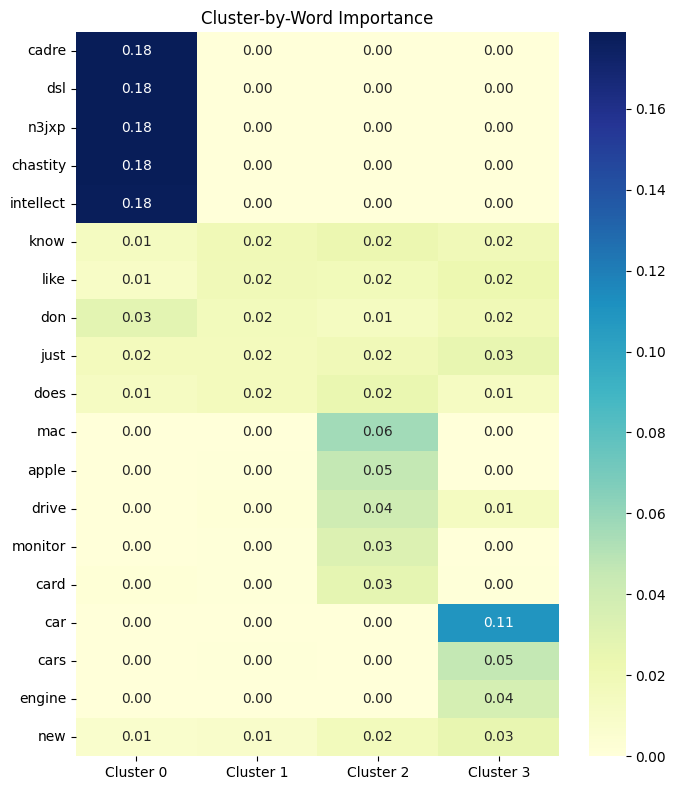

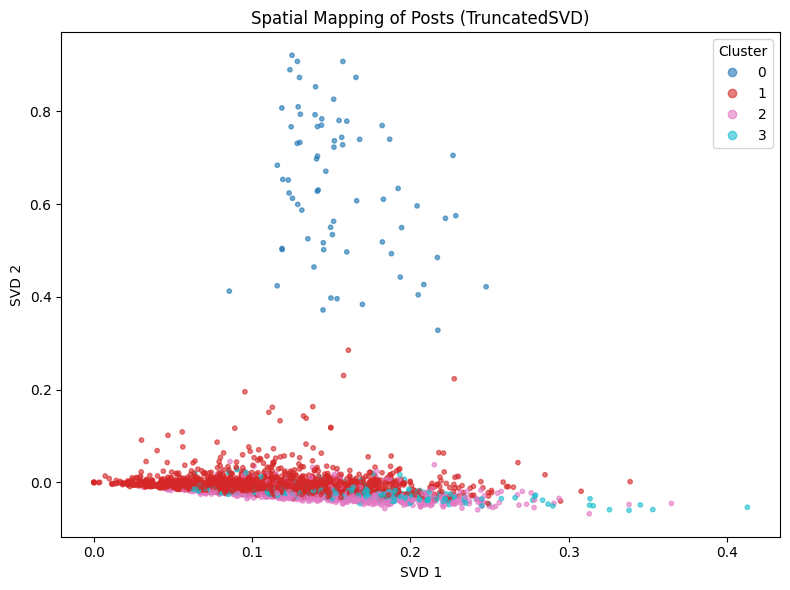

In [4]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_tfidf)

terms = tfidf_vec.get_feature_names_out()
order = kmeans.cluster_centers_.argsort(axis=1)[:, ::-1]

print("Top 8 words per cluster:")
for c in range(4):
    print(f"Cluster {c}: {[terms[i] for i in order[c, :8]]}")

# Heatmap
heat_words = []
for c in range(4):
    for i in order[c, :5]:
        if terms[i] not in heat_words:
            heat_words.append(terms[i])
word_idx = [list(terms).index(w) for w in heat_words]
heat_df = pd.DataFrame(
    kmeans.cluster_centers_[:, word_idx].T,
    index=heat_words,
    columns=[f"Cluster {c}" for c in range(4)],
)
plt.figure(figsize=(7, 8))
sns.heatmap(heat_df, cmap="YlGnBu", annot=True, fmt=".2f")
plt.title("Cluster-by-Word Importance")
plt.tight_layout()
plt.savefig("cluster_heatmap.png", dpi=150)
plt.show()

# 2D spatial mapping
svd = TruncatedSVD(n_components=2, random_state=42)
coords = svd.fit_transform(X_tfidf)
plt.figure(figsize=(8, 6))
scatter = plt.scatter(coords[:, 0], coords[:, 1], c=df["cluster"],
                      cmap="tab10", s=10, alpha=0.6)
plt.legend(*scatter.legend_elements(), title="Cluster")
plt.xlabel("SVD 1")
plt.ylabel("SVD 2")
plt.title("Spatial Mapping of Posts (TruncatedSVD)")
plt.tight_layout()
plt.savefig("spatial_mapping.png", dpi=150)
plt.show()

In [5]:
# Challenge 1: cleaner vectorizer
custom_stops = {"know", "like", "just", "think", "does", "use", "thanks",
                "don", "did", "ve", "really", "good", "need"}
clean_stops = list(ENGLISH_STOP_WORDS.union(custom_stops))

clean_vec = TfidfVectorizer(
    token_pattern=r"\b[a-zA-Z]{3,}\b",
    max_df=0.5,
    min_df=5,
    max_features=4000,
    stop_words=clean_stops,
)
X_clean = clean_vec.fit_transform(df["text"])
kmeans_clean = KMeans(n_clusters=4, random_state=42, n_init=10)
df["cluster_clean"] = kmeans_clean.fit_predict(X_clean)

clean_terms = clean_vec.get_feature_names_out()
clean_order = kmeans_clean.cluster_centers_.argsort(axis=1)[:, ::-1]
print("Cleaned top words per cluster:")
for c in range(4):
    print(f"Cluster {c}: {[clean_terms[i] for i in clean_order[c, :8]]}")

# Challenge 2: crosstab
print("\nTrue label vs cluster:")
print(pd.crosstab(df["true_label"], df["cluster"]))

# Challenge 3: length bias
lengths = df["text"].str.len()
longest, shortest = lengths.idxmax(), lengths.idxmin()
for name, M in [("BoW", X_bow), ("TF-IDF", X_tfidf)]:
    n_long = np.linalg.norm(M[longest].toarray())
    n_short = np.linalg.norm(M[shortest].toarray())
    print(f"{name}: longest norm = {n_long:.3f}, shortest norm = {n_short:.3f}")

# Challenge 4: explainability
def explain_document(doc_id, matrix, vectorizer, top_n=5):
    """Return top_n (term, weight) pairs for one document."""
    row = matrix[doc_id].tocoo()
    terms = vectorizer.get_feature_names_out()
    pairs = sorted(zip(row.col, row.data), key=lambda x: x[1], reverse=True)[:top_n]
    return [(terms[i], float(w)) for i, w in pairs]

result = explain_document(412, X_tfidf, tfidf_vec, top_n=5)
print("\nDocument #412 top features:")
for term, weight in result:
    print(f"  {term}: {weight:.4f}")

Cleaned top words per cluster:
Cluster 0: ['cadre', 'dsl', 'chastity', 'intellect', 'surrender', 'shameful', 'skepticism', 'geb']
Cluster 1: ['people', 'time', 'edu', 'used', 'information', 'want', 'help', 'make']
Cluster 2: ['mac', 'apple', 'drive', 'monitor', 'card', 'scsi', 'video', 'simms']
Cluster 3: ['car', 'cars', 'engine', 'new', 'ford', 'oil', 'dealer', 'miles']

True label vs cluster:
cluster                 0    1    2    3
true_label                              
comp.sys.mac.hardware   0  279  629    2
rec.autos               0  377    2  526
sci.electronics         0  850   66   24
sci.med                71  875    2    0
BoW: longest norm = 276.286, shortest norm = 2.000
TF-IDF: longest norm = 1.000, shortest norm = 1.000

Document #412 top features:
  discussion: 0.4524
  feel: 0.3989
  days: 0.3855
  need: 0.2885
  meant: 0.2667


Challenge 2

In [6]:
bi_vec = TfidfVectorizer(stop_words="english", ngram_range=(1, 2),
                         max_features=4000, min_df=5)
X_bi = bi_vec.fit_transform(df["text"])
km_bi = KMeans(n_clusters=4, random_state=42, n_init=10)
df["cluster_bi"] = km_bi.fit_predict(X_bi)

print(pd.crosstab(df["true_label"], df["cluster_bi"]))
bi_terms = bi_vec.get_feature_names_out()
bi_order = km_bi.cluster_centers_.argsort(axis=1)[:, ::-1]
for c in range(4):
    print(f"Cluster {c}: {[bi_terms[i] for i in bi_order[c, :8]]}")

cluster_bi               0   1    2    3
true_label                              
comp.sys.mac.hardware  309   0  599    2
rec.autos              396   0    2  507
sci.electronics        888   0   34   18
sci.med                876  71    1    0
Cluster 0: ['know', 'like', 'don', 'just', 'use', 'does', 'thanks', 'good']
Cluster 1: ['intellect geb', 'shameful surrender', 'cadre', 'cadre dsl', 'geb cadre', 'dsl', 'surrender soon', 'dsl pitt']
Cluster 2: ['mac', 'apple', 'drive', 'monitor', 'card', 'scsi', 'does', 'know']
Cluster 3: ['car', 'cars', 'engine', 'new', 'just', 'dealer', 'ford', 'like']
